In [ ]:
!pip -q install -U transformers datasets accelerate evaluate scikit-learn pandas matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyTorch: 2.14.1+cpu
Device: cpu


In [3]:
dataset = load_dataset("PolyAI/banking77")

print(dataset)
print("\\nExample:")
print(dataset["train"][0])

README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})
\nExample:
{'text': 'I am still waiting on my card?', 'label': 11}


In [4]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
display(train_df.head())
print("\\nMissing values:")
print(train_df.isnull().sum())
print("\\nNumber of intent classes:", train_df["label"].nunique())

Train shape: (10003, 2)
Test shape: (3080, 2)


,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11
3,Can I track my card while it is in the process...,11
4,"How do I know if I will get my card, or if it ...",11


\nMissing values:
text     0
label    0
dtype: int64
\nNumber of intent classes: 77


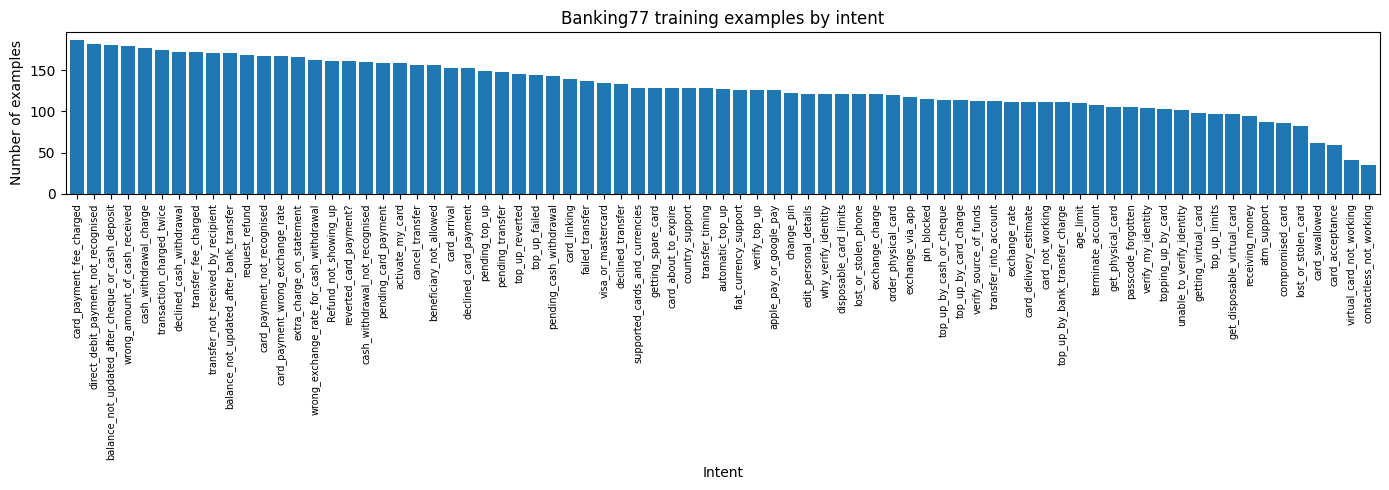

Number of intents: 77
Smallest class size: 35
Largest class size: 187


In [5]:
label_names = dataset["train"].features["label"].names
train_df["intent"] = train_df["label"].map(lambda x: label_names[x])

intent_counts = train_df["intent"].value_counts()
plt.figure(figsize=(14, 5))
intent_counts.plot(kind="bar", width=0.85)
plt.title("Banking77 training examples by intent")
plt.xlabel("Intent")
plt.ylabel("Number of examples")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

print("Number of intents:", len(label_names))
print("Smallest class size:", intent_counts.min())
print("Largest class size:", intent_counts.max())

In [6]:
MODEL_CHECKPOINT = "huawei-noah/TinyBERT_General_4L_312D"
NUM_LABELS = len(label_names)
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

# Create a validation split from the official training set.
split_dataset = dataset["train"].train_test_split(
    test_size=0.1,
    seed=SEED,
    stratify_by_column="label"
)
train_data = split_dataset["train"]
validation_data = split_dataset["test"]
test_data = dataset["test"]

print("Training:", len(train_data))
print("Validation:", len(validation_data))
print("Test:", len(test_data))

config.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Training: 9002
Validation: 1001
Test: 3080


In [7]:
def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_train = train_data.map(tokenize_batch, batched=True)
tokenized_validation = validation_data.map(tokenize_batch, batched=True)
tokenized_test = test_data.map(tokenize_batch, batched=True)

# Trainer expects the target column to be named labels.
tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_validation = tokenized_validation.rename_column("label", "labels")
tokenized_test = tokenized_test.rename_column("label", "labels")

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(tokenized_train[0].keys())

Map:   0%|          | 0/9002 [00:00<?, ? examples/s]

Map:   0%|          | 0/1001 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

dict_keys(['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'])


In [8]:
id2label = {i: name for i, name in enumerate(label_names)}
label2id = {name: i for i, name in enumerate(label_names)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded.")
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 62.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 62.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Model loaded.
Trainable parameters: 14374349


In [9]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )
    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    }


training_args = TrainingArguments(
    output_dir="./smartdesk_tinybert_checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=4,
    weight_decay=0.01,
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer is ready.")

Trainer is ready.


In [10]:
train_result = trainer.train()
print(train_result)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,4.006991,3.949237,0.117882,0.067042,0.107175,0.047096
2,3.706248,3.653436,0.122877,0.101605,0.111002,0.050296
3,3.530987,3.508596,0.156843,0.102475,0.139889,0.074285
4,3.478709,3.459432,0.170829,0.084445,0.150396,0.082274


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2252, training_loss=3.770884848403253, metrics={'train_runtime': 1541.3151, 'train_samples_per_second': 23.362, 'train_steps_per_second': 1.461, 'total_flos': 40318236639264.0, 'train_loss': 3.770884848403253, 'epoch': 4.0})


In [11]:
test_results = trainer.evaluate(tokenized_test)
print("TinyBERT test results:")
for metric, value in test_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro
3.478709,3.519727,4,0.159740,0.140651,0.159740,0.088646


TinyBERT test results:
eval_loss: 3.5197
eval_accuracy: 0.1597
eval_precision_macro: 0.1407
eval_recall_macro: 0.1597
eval_f1_macro: 0.0886


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


                                                  precision    recall  f1-score   support

                                activate_my_card     0.1719    0.9500    0.2912        40
                                       age_limit     0.0000    0.0000    0.0000        40
                         apple_pay_or_google_pay     0.0000    0.0000    0.0000        40
                                     atm_support     0.0000    0.0000    0.0000        40
                                automatic_top_up     0.0000    0.0000    0.0000        40
         balance_not_updated_after_bank_transfer     0.0000    0.0000    0.0000        40
balance_not_updated_after_cheque_or_cash_deposit     0.0903    0.3250    0.1413        40
                         beneficiary_not_allowed     0.0000    0.0000    0.0000        40
                                 cancel_transfer     0.2011    0.8750    0.3271        40
                            card_about_to_expire     1.0000    0.0250    0.0488        40
         

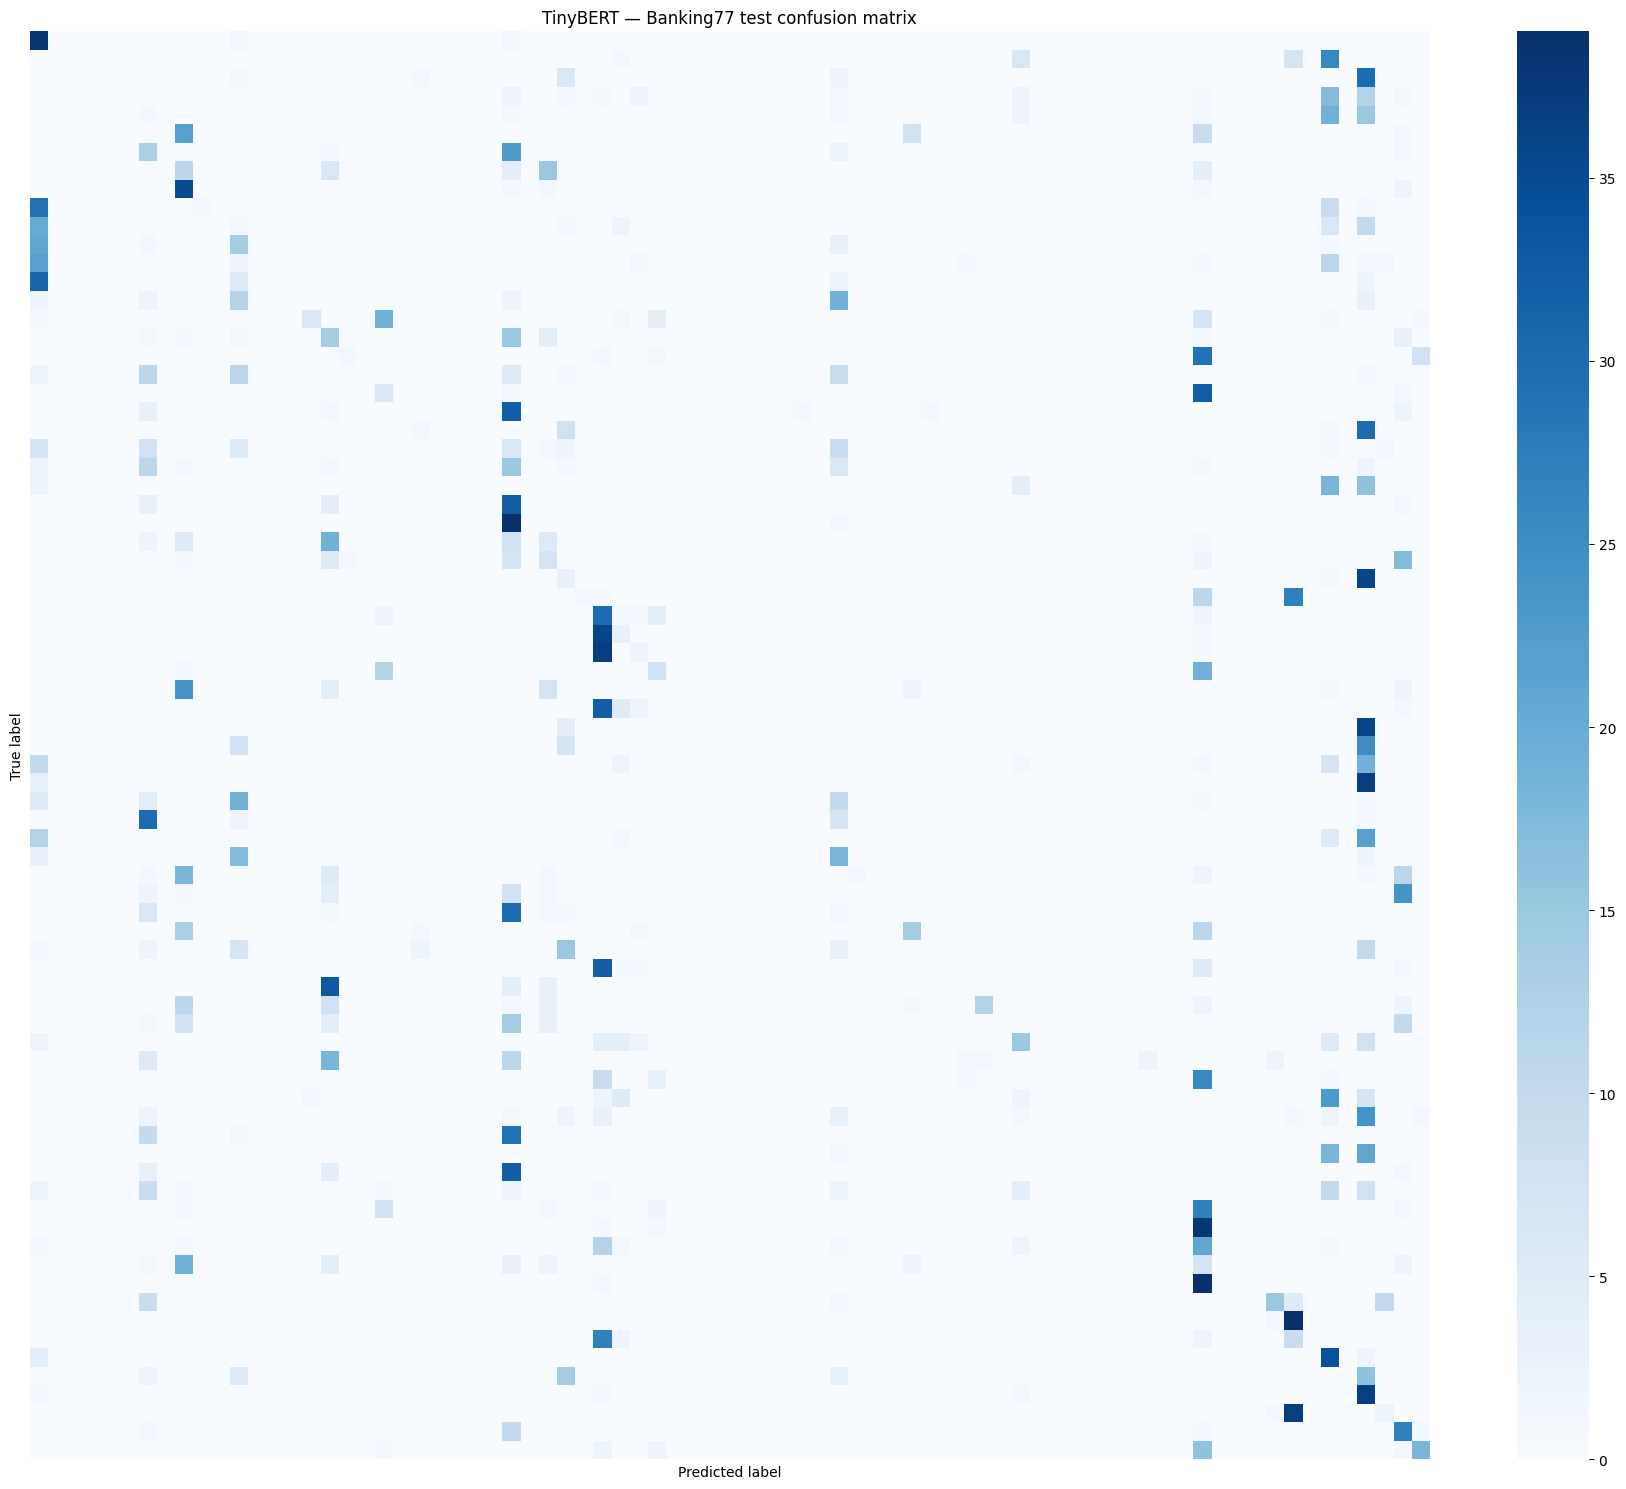

In [12]:
test_output = trainer.predict(tokenized_test)
test_predictions = np.argmax(test_output.predictions, axis=1)
test_labels = test_output.label_ids

print(classification_report(
    test_labels,
    test_predictions,
    target_names=label_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(18, 15))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("TinyBERT — Banking77 test confusion matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

In [13]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=100000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=SEED
    ))
])

baseline.fit(dataset["train"]["text"], dataset["train"]["label"])
baseline_predictions = baseline.predict(dataset["test"]["text"])
baseline_precision, baseline_recall, baseline_f1, _ = precision_recall_fscore_support(
    dataset["test"]["label"],
    baseline_predictions,
    average="macro",
    zero_division=0
)
baseline_accuracy = accuracy_score(dataset["test"]["label"], baseline_predictions)

comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": baseline_accuracy,
        "Macro Precision": baseline_precision,
        "Macro Recall": baseline_recall,
        "Macro F1": baseline_f1
    },
    {
        "Model": "TinyBERT",
        "Accuracy": accuracy_score(test_labels, test_predictions),
        "Macro Precision": precision_recall_fscore_support(test_labels, test_predictions, average="macro", zero_division=0)[0],
        "Macro Recall": precision_recall_fscore_support(test_labels, test_predictions, average="macro", zero_division=0)[1],
        "Macro F1": precision_recall_fscore_support(test_labels, test_predictions, average="macro", zero_division=0)[2]
    }
])

display(comparison.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,TF-IDF + Logistic Regression,0.8588,0.8681,0.8588,0.8581
1,TinyBERT,0.1597,0.1407,0.1597,0.0886


In [14]:
def predict_intent(message, model_trainer=trainer, tokenizer=tokenizer):
    model_trainer.model.eval()
    inputs = tokenizer(
        message,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )
    model_device = next(model_trainer.model.parameters()).device
    inputs = {key: value.to(model_device) for key, value in inputs.items()}

    with torch.no_grad():
        logits = model_trainer.model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    predicted_id = int(torch.argmax(probabilities).item())
    confidence = float(probabilities[predicted_id].item())

    return {
        "message": message,
        "predicted_intent": label_names[predicted_id],
        "confidence": confidence
    }


examples = [
    "My card was charged twice for the same purchase.",
    "I forgot my banking app password and cannot log in.",
    "I transferred money but the recipient has not received it."
]

for message in examples:
    result = predict_intent(message)
    print("Message:", result["message"])
    print("Predicted intent:", result["predicted_intent"])
    print("Confidence:", f'{result["confidence"]:.2%}')
    print("-" * 60)

Message: My card was charged twice for the same purchase.
Predicted intent: cash_withdrawal_charge
Confidence: 4.63%
------------------------------------------------------------
Message: I forgot my banking app password and cannot log in.
Predicted intent: passcode_forgotten
Confidence: 3.19%
------------------------------------------------------------
Message: I transferred money but the recipient has not received it.
Predicted intent: cancel_transfer
Confidence: 4.09%
------------------------------------------------------------


In [15]:
REVIEW_THRESHOLD = 0.60

def classify_ticket(message):
    result = predict_intent(message)
    result["status"] = (
        "Needs human review"
        if result["confidence"] < REVIEW_THRESHOLD
        else "Automatically classified"
    )
    return result

classify_ticket("I need help with a card payment that failed.")

{'message': 'I need help with a card payment that failed.',
 'predicted_intent': 'declined_cash_withdrawal',
 'confidence': 0.048066169023513794,
 'status': 'Needs human review'}

In [16]:
SAVE_DIR = "./smartdesk_tinybert_model"

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

print("Model saved to:", SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: ./smartdesk_tinybert_model


In [17]:
# Uncomment after saving or uploading the model directory:
#
from transformers import AutoTokenizer, AutoModelForSequenceClassification

saved_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
saved_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR)

print("Saved TinyBERT model loaded successfully.")

Loading weights:   0%|          | 0/73 [00:00<?, ?it/s]

Saved TinyBERT model loaded successfully.
